# Flow Matching Inference

In this notebook we will show the process of using a trained flow model to make predictions

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

from abc import ABC, abstractmethod

import torch
import xarray as xr
import numpy as np

from src.config import load_config

In [2]:
CONFIG_PATH = str(Path.cwd().parent) + "/src/config/config.yaml"

DATA_PATH = "/gws/ssde/j25b/ai4climate/user/jar212/sg-workshop-2026-flow/data/jakarta128_8km_to_2km_imperfect"
PREDICTORS_PATH = DATA_PATH + "/predictors"
TARGETS_PATH = DATA_PATH + "/targets"
STATIC_PATH = DATA_PATH + "/static/static_128jakarta_sqrt_normalised.nc"

MODEL_PATH = "/gws/ssde/j25b/ai4climate/user/jar212/sg-workshop-2026-flow/outputs/model.pth"
TRANSFORMS_PATH = "/gws/ssde/j25b/ai4climate/user/jar212/sg-workshop-2026-flow/outputs/transforms.json"

OUTPUT_PATH = "/gws/ssde/j25b/ai4climate/user/jar212/sg-workshop-2026-flow/outputs"

In [3]:
NUM_WORKERS = 0
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print(f"Using device: {DEVICE}")

config = load_config(CONFIG_PATH)

Using device: cpu


In [4]:

split = "test"
inference_dates = getattr(config, split).date_ranges
print(inference_dates)

[('2050-01-01', '2059-12-30')]


In [48]:
from src.transforms import Transform, load_transforms

In [49]:
transforms: dict[str, Transform] = load_transforms(TRANSFORMS_PATH)

In [50]:
print(transforms)

{'predictors': {'hus200': <src.transforms.ComposeTransform object at 0x7f68d85812e0>, 'hus500': <src.transforms.ComposeTransform object at 0x7f69c1d0a3f0>, 'hus700': <src.transforms.ComposeTransform object at 0x7f68d857b6b0>, 'hus850': <src.transforms.ComposeTransform object at 0x7f68d8597260>, 'ta200': <src.transforms.ComposeTransform object at 0x7f68d83e6dd0>, 'ta500': <src.transforms.ComposeTransform object at 0x7f68d83e6e50>, 'ta700': <src.transforms.ComposeTransform object at 0x7f68d8413310>, 'ta850': <src.transforms.ComposeTransform object at 0x7f68d8413690>, 'ua200': <src.transforms.ComposeTransform object at 0x7f6915a0e9f0>, 'ua500': <src.transforms.ComposeTransform object at 0x7f68d85d6210>, 'ua700': <src.transforms.ComposeTransform object at 0x7f68d84270c0>, 'ua850': <src.transforms.ComposeTransform object at 0x7f68d84271b0>, 'va200': <src.transforms.ComposeTransform object at 0x7f68d8426cb0>, 'va500': <src.transforms.ComposeTransform object at 0x7f68d8426c60>, 'va700': <src.

In [51]:
from src.dataset import V3Dataset

In [ ]:
inference_dataset = V3Dataset(
    predictors_path=PREDICTORS_PATH,
    targets_path=TARGETS_PATH,
    config=config,
    date_ranges=inference_dates,
    transforms=transforms,
    static_path=STATIC_PATH,
)
batch_size = config.training.batch_size
inference_dataloader = torch.utils.data.DataLoader(
    inference_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

In [53]:
from src.network import ADM


static_variables = config.static or []
if static_variables:
    print(f"Using static variables: {static_variables}")
else:
    print("Not using static variables")
if config.pos_emb:
    print("Using sinusoidal positional embeddings (4 channels)")
num_conditioning_variables = (
    len(config.predictors) + len(static_variables) + (4 if config.pos_emb else 0)
)

model = ADM(
    num_conditioning_variables=num_conditioning_variables,
    num_target_variables=len(config.targets),
    **config.model.model_dump(),
).to(DEVICE)

Using static variables: ['orog', 'lsm']
Using sinusoidal positional embeddings (4 channels)


In [54]:
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
print(f"Loaded model from {MODEL_PATH}")

Loaded model from /gws/ssde/j25b/ai4climate/user/jar212/sg-workshop-2026-flow/outputs/model.pth


In [55]:
class GaussianDistribution:
    """Gaussian distribution sampler."""

    def __init__(self, mean: float, std: float, device: torch.device):
        """Initialise Gaussian distribution sampler.

        Args:
            mean: Mean of the Gaussian distribution.
            std: Standard deviation of the Gaussian distribution.
            device: Device to place samples on.
        """
        self.mean = mean
        self.std = std
        self.device = device

    def sample(self, shape: tuple) -> torch.Tensor:
        return torch.normal(self.mean, self.std, size=shape, device=self.device)

In [56]:
source_sampler = GaussianDistribution(
    mean=config.source.mean, std=config.source.std, device=DEVICE
)

In [57]:
class Solver(ABC):
    def __init__(
        self,
        n_steps: int,
        alpha: float,
        model: torch.nn.Module,
        device: torch.device,
    ):
        """Initialise.

        Args:
            n_steps: Number of steps.
            alpha: Exponent for the time-stepping scheme. If alpha=1, then the time steps
                are uniformly spaced between 0 and 1 (constant step size). If alpha>1, then the
                step size is smaller near t=1 (the data/target side) and larger near t=0 (the
                noise/source side).
            model: Neural network model representing the velocity/vector field.
            device: Device
        """
        self.n_steps = n_steps
        self.alpha = alpha
        self.model = model
        self.device = device
        self.time_steps = (
            1 - (1 - torch.tensor(range(self.n_steps + 1)) / self.n_steps) ** self.alpha
        )  # shape (n_steps + 1, )
        self.step_sizes = self.time_steps[1:] - self.time_steps[:-1]  # shape (n_steps, )

    def simulate(
        self, x_0: torch.Tensor, predictors: torch.Tensor, static: torch.Tensor | None
    ) -> torch.Tensor:
        """Simulate the ODE from t=0 to t=1.

        Args:
            x_0: Tensor of shape (batch_size, num_target_variables, height, width)
            predictors: Predictor variables,
                shape (batch_size, num_predictor_variables, height, width)
            static: Static fields (e.g., orography), shape (batch_size, num_static_variables, height, width).
                If static fields are not used, this should be None.

        Returns:
            x_1: Tensor of shape (batch_size, num_target_variables, height, width)
        """
        x_current = x_0.to(self.device)

        for idx, step_size in enumerate(self.step_sizes):
            t_current = self.time_steps[idx].item()
            t_current = torch.full(
                (x_current.shape[0], 1), t_current, device=self.device
            )  # shape (batch_size, 1)
            x_current = self.step(x_current, t_current, predictors, static, step_size.item())

        return x_current

    def _get_velocity(
        self,
        x_current: torch.Tensor,
        t_current: torch.Tensor,
        predictors: torch.Tensor,
        static: torch.Tensor | None,
    ) -> torch.Tensor:
        """Returns the velocity/vector field predicted by the model at (x_current, t_current)."""
        conditioning = predictors if static is None else torch.cat([predictors, static], dim=1)
        return self.model(x_current, t_current, conditioning)

    @abstractmethod
    def step(
        self,
        x_current: torch.Tensor,
        t_current: torch.Tensor,
        predictors: torch.Tensor,
        static: torch.Tensor | None,
        step_size: float,
    ) -> torch.Tensor:
        """Take a single step of the ODE solver.

        Args:
            x_current: Current state, shape (batch_size, num_target_variables, height, width)
            t_current: Current time between 0 and 1, shape (batch_size, 1)
            predictors: Predictor variables,
                shape (batch_size, num_predictor_variables, height, width)
            static: Static fields (e.g., orography), shape (batch_size, num_static_variables, height, width).
                If static fields are not used, this should be None.
            step_size: Step size for this step.

        Returns:
            x_next: Next state, shape (batch_size, num_target_variables, height, width)
        """
        pass

In [58]:
class EulerSolver(Solver):
    def step(
        self,
        x_current: torch.Tensor,
        t_current: torch.Tensor,
        predictors: torch.Tensor,
        static: torch.Tensor | None,
        step_size: float,
    ) -> torch.Tensor:
        x_next = x_current + step_size * self._get_velocity(
            x_current, t_current, predictors, static
        )
        return x_next

In [59]:
class HeunSolver(Solver):
    def step(
        self,
        x_current: torch.Tensor,
        t_current: torch.Tensor,
        predictors: torch.Tensor,
        static: torch.Tensor | None,
        step_size: float,
    ) -> torch.Tensor:
        dx = self._get_velocity(x_current, t_current, predictors, static)
        x_next_estimate = x_current + step_size * dx
        t_next = t_current + step_size
        dx_next = self._get_velocity(x_next_estimate, t_next, predictors, static)
        x_next = x_current + (step_size / 2) * (dx + dx_next)
        return x_next

In [60]:
solver_type = "euler"
n_steps = 100
alpha = 2

if solver_type == "euler":
    solver = EulerSolver(n_steps=n_steps, alpha=alpha, model=model, device=DEVICE)
elif solver_type == "heun":
    solver = HeunSolver(n_steps=n_steps, alpha=alpha, model=model, device=DEVICE)
else:
    raise ValueError(f"Unsupported solver type: {solver_type}")

In [61]:
n_samples = 8

In [62]:
prediction_batches: list[torch.Tensor] = []
target_batches: list[torch.Tensor] = []

for batch in inference_dataloader:
    print(f"Generating {n_samples} samples for batch of size {batch[0].shape[0]}")
    
    predictors, targets, _, static = batch

    target_batches.append(targets.cpu())
    
    samples: list[torch.Tensor] = []  # list of samples of shape (batch_size, num_target_variables, lat, lon)
    for _ in range(n_samples):
        # Resample source for each sample
        x_0 = source_sampler.sample(
            (
                predictors.shape[0],
                len(config.targets),
                predictors.shape[2],
                predictors.shape[3],
            )
        )  # shape (batch_size, num_target_variables, lat, lon)

        predictors = predictors.to(DEVICE)
        x_0 = x_0.to(DEVICE)
        static = static.to(DEVICE) if static.shape[1] > 0 else None
        
        model.eval()
        with torch.no_grad():
            x_1 = solver.simulate(
                x_0=x_0, predictors=predictors, static=static
            )  # shape (batch_size, num_target_variables, lat, lon)
            samples.append(x_1.cpu())
            
    samples_tensor = torch.stack(
        samples, dim=0
    )  # shape (n_samples, batch_size, num_target_variables, lat, lon)
    prediction_batches.append(samples_tensor)

predictions = torch.cat(
    prediction_batches, dim=1
).numpy()  # shape (n_samples, time, num_target_variables, lat, lon)

targets_tensor = torch.cat(
    target_batches, dim=0
).numpy()  # shape (time, num_target_variables, lat, lon)

Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 16
Generating 8 samples for batch of size 13


In [63]:
target_var_names: list[str] = list(config.targets.keys())  # list of target variable names

data_vars: dict[str, xr.DataArray] = {}
for idx, target in enumerate(target_var_names):
    # Inverse any transforms applied
    print(f"Applying inverse transform to target variable '{target}'")
    target_transform = transforms["targets"][target]
    predictions[:, :, idx, :, :] = target_transform.inverse_transform(
        predictions[:, :, idx, :, :]
    )
    targets_tensor[:, idx, :, :] = target_transform.inverse_transform(
        targets_tensor[:, idx, :, :]
    )

    # Propogate relevant attributes from the target variable
    target_attrs = inference_dataset.target_attrs[target]
    attrs = {
        key: target_attrs[key] for key in ["units", "standard_name"] if key in target_attrs
    }

    data_vars[f"pred_{target}"] = (
        ("sample", "input", "time", "grid_latitude", "grid_longitude"),
        np.expand_dims(
            predictions[:, :, idx, :, :], axis=1
        ),  # expand_dims adds 'dummy' input axis
        attrs,
    )

    data_vars[f"target_{target}"] = (
        ("input", "time", "grid_latitude", "grid_longitude"),
        np.expand_dims(targets_tensor[:, idx, :, :], axis=0),
        attrs,
    )

Applying inverse transform to target variable 'pr'


In [65]:
print("Forming xarray Dataset and saving to netCDF")

input_descriptor = "jakarta128_8km_to_2km_imperfect"

ds = xr.Dataset(
    data_vars=data_vars,
    coords={
        "sample": np.arange(n_samples),
        "input": [input_descriptor],
        "time": inference_dataset.time,
        "grid_latitude": inference_dataset.target_lat,
        "grid_longitude": inference_dataset.target_lon,
    },
    attrs={
        "solver_type": solver_type,
        "n_steps": n_steps,
        "alpha": alpha,
    },
)

output_file = f"{OUTPUT_PATH}/predictions.nc"
ds.to_netcdf(output_file, format="NETCDF4", engine="netcdf4")
print(f"Predictions saved to {output_file}")

Forming xarray Dataset and saving to netCDF
Predictions saved to /gws/ssde/j25b/ai4climate/user/jar212/sg-workshop-2026-flow/outputs/predictions.nc


In [2]:
PREDICTIONS_PATH = "/gws/ssde/j25b/ai4climate/user/jar212/sg-workshop-2026-flow/outputs/predictions.nc"

In [3]:
predictions_ds = xr.open_dataset(PREDICTIONS_PATH)
print(predictions_ds)

<xarray.Dataset> Size: 215MB
Dimensions:         (sample: 8, input: 1, time: 365, grid_latitude: 128,
                     grid_longitude: 128)
Coordinates:
  * sample          (sample) int64 64B 0 1 2 3 4 5 6 7
  * input           (input) <U31 124B 'jakarta128_8km_to_2km_imperfect'
  * time            (time) datetime64[ns] 3kB 2050-01-01 ... 2050-12-31
  * grid_latitude   (grid_latitude) float64 1kB -7.29 -7.272 ... -5.022 -5.004
  * grid_longitude  (grid_longitude) float64 1kB 105.7 105.7 ... 107.9 107.9
Data variables:
    pred_pr         (sample, input, time, grid_latitude, grid_longitude) float32 191MB ...
    target_pr       (input, time, grid_latitude, grid_longitude) float32 24MB ...
Attributes:
    solver_type:  euler
    n_steps:      100
    alpha:        2


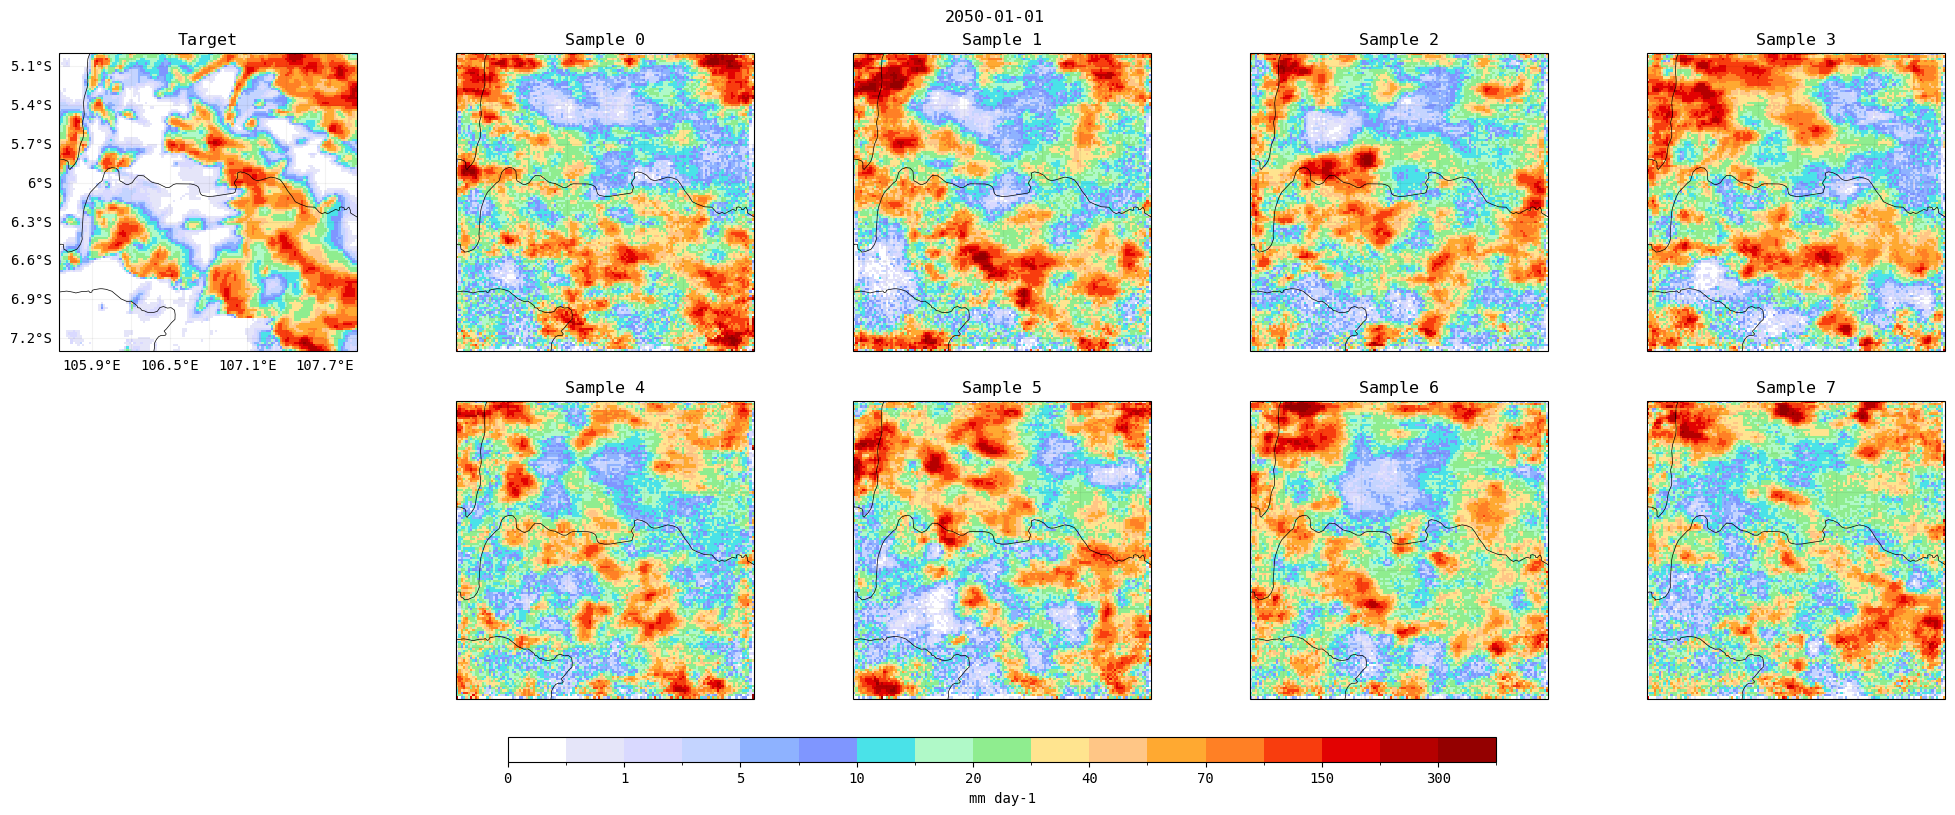

In [4]:
from src.plotting import plot_target_vs_predictions

plot_target_vs_predictions(
    predictions_ds,
    time_idx=0,
    variable="pr",
    input_idx=0,
    n_samples=8,
    max_sample_cols=4,
)